# Phase G: Ergebnis nach Folie 5

Schritte 21 bis 24 aus `LERNPLAN.md`.

Am Ende soll das Projekt drei Dinge liefern: **Alarm** (eine Station verändert sich), **Fehler erkennen** (an dieser Station stimmt etwas nicht) und **Fehler unterteilen**. Für das Unterteilen gibt Folie 5 des Projektpartners drei Klassen vor:

| Klasse | Empfehlung |
|---|---|
| Station läuft gut | kein Handlungsbedarf |
| Station läuft schlechter als möglich, Technik in Ordnung | Regelparameter optimieren |
| Regelventil schließt nicht | Regelventil tauschen |

Hier wird diese Tabelle für alle 96 Zähler gebaut, aus dem, was in Phase B bis F funktioniert hat. Die Reihenfolge ist wie im Team (Notebook 28 und 31): erst das Ventil, dann für den Rest „Optimum oder schlechter“.

## Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
METER_DIR = ROOT / "data" / "processed" / "real_meters"
LERNPFAD = ROOT / "data" / "processed" / "lernpfad"
BILDER = ROOT / "docs" / "assets" / "lernpfad"

sys.path.insert(0, str(ROOT))

## Schritt 21: Kennzahlen für alle 96 Zähler

Dieselben Kennzahlen wie in Phase B, jetzt auch für die 40 nie begangenen Zähler:

- `nachtfluss`: Median Durchfluss im Sommer 2024, 0 bis 5 Uhr (Ventil)
- `winter_ruecklauf`: Median Rücklauf im Winter 2023/24
- `winter_spreizung`: Median Spreizung im Winter 2023/24, nur Stunden mit Durchfluss

Für alle gilt derselbe Stand wie in Phase B: nur Daten vor dem Stichtag 01.09.2024, bei den beiden Augustfällen vor ihrer Begehung.

In [2]:
labels = pd.read_csv(ROOT / "data" / "processed" / "modell_labels.csv", parse_dates=["erste_begehung"])
begehung = labels.set_index("zaehler")["erste_begehung"]

In [3]:
zeilen = []
for datei in sorted(METER_DIR.glob("*.csv")):
    z = int(datei.stem)
    d = pd.read_csv(datei, parse_dates=["Timestamp"])

    ende = pd.Timestamp("2024-09-01")
    if z in begehung.index and begehung[z] < ende:
        ende = begehung[z]
    d = d[d["Timestamp"] < ende]

    sommer = d[(d["Timestamp"] >= "2024-06-01") & (d["Timestamp"] < "2024-09-01")]
    nacht = sommer[sommer["Timestamp"].dt.hour < 5]
    winter = d[(d["Timestamp"] >= "2023-10-01") & (d["Timestamp"] < "2024-04-01")]
    mit_fluss = winter[winter["Volume flow (l/h)"] > 0]

    zeilen.append({
        "zaehler": z,
        "nachtfluss": nacht["Volume flow (l/h)"].median(),
        "winter_ruecklauf": winter["Return temperature (°C)"].median(),
        "winter_spreizung": mit_fluss["Temperature difference (°C)"].median(),
    })

kz = pd.DataFrame(zeilen).set_index("zaehler")
kz["begangen"] = kz.index.isin(labels["zaehler"])
kz.describe().round(1)

,nachtfluss,winter_ruecklauf,winter_spreizung
count,87.0,93.0,90.0
mean,139.2,47.2,23.6
std,604.0,13.0,10.9
min,0.0,25.4,0.1
25%,0.0,37.9,17.3
50%,0.0,45.7,26.2
75%,18.5,54.9,31.1
max,5120.5,77.6,40.6


Wie groß sind die Stationen? Der Anschlusswert steht in `hast_features.csv`. Die begangenen Stationen, an denen alles in Phase B gelernt wurde, haben 5 bis 24 kW:

In [4]:
anschluss = pd.read_csv(ROOT / "data" / "processed" / "hast_features.csv").set_index("Zählernummer")["anschlusswert_kw"]
kz["anschluss_kw"] = anschluss.reindex(kz.index)
kz.groupby("begangen")["anschluss_kw"].describe()

,count,mean,std,min,25%,50%,75%,max
begangen,,,,,,,,
False,30.0,28.666667,89.408529,7.0,8.0,10.0,14.5,500.0
True,55.0,10.945455,3.917757,5.0,8.0,10.0,13.5,24.0


In [5]:
kz["ausserhalb"] = kz["anschluss_kw"].isna() | (kz["anschluss_kw"] > kz.loc[kz["begangen"], "anschluss_kw"].max())
kz["ausserhalb"].sum()

np.int64(13)

- Nachtdurchfluss gibt es für 87 Zähler, Winterwerte für 90 bis 93. Wo Sommer- oder Winterdaten fehlen, kann die jeweilige Regel nicht urteilen.
- Unter den nie begangenen sind ein paar viel größere Stationen (bis 500 kW) und welche ohne Anschlusswert. Bei ihnen ist zum Beispiel ein Nachtdurchfluss von 70 l/h vielleicht ganz normal. Sie werden markiert (`ausserhalb`), weil die Regeln nur an Stationen von 5 bis 24 kW geprüft wurden.

## Schritt 22: Ventil-Verdacht

Die Regel aus Phase B: Fließt im Sommer nachts Wasser, schließt das Ventil nicht (AUC 0,88). Für eine Klasse braucht es aber eine Grenze. Aus der Tabelle in Phase B, Schritt 7:

| Alarm, wenn nachts mehr fließt als | Alarme | Precision | Recall |
|---|---|---|---|
| 0 l/h | 14 | 64 % | 82 % |
| 50 l/h | 9 | 78 % | 64 % |
| 100 l/h | 6 | 83 % | 45 % |

„Regelventil tauschen“ heißt, dass ein Techniker hinfährt und ein Teil tauscht. Dann zählt die Precision, aber es soll noch mehr als die Hälfte der Ventile gefunden werden. Das ist die Grenze **50 l/h**. Ehrlich dazu: Gewählt wurde sie auf denselben 53 Stationen, auf denen sie gleich geprüft wird. Precision und Recall unten sind deshalb eher zu gut.

In [6]:
kz["ventil_verdacht"] = kz["nachtfluss"] > 50

In [7]:
pruefung = kz[kz["begangen"]].join(labels.set_index("zaehler")["ventil"])
pd.crosstab(pruefung["ventil_verdacht"], pruefung["ventil"])

ventil,False,True
ventil_verdacht,,
False,43,4
True,2,7


9 begangene Stationen mit Verdacht, 7 davon mit Ventilbefund (Precision 78 %). Gefunden werden 7 der 11 Ventile (Recall 64 %). Das sind genau die Werte aus Phase B.

Und die nie begangenen Zähler mit Verdacht:

In [8]:
kz[~kz["begangen"] & kz["ventil_verdacht"]][["nachtfluss", "winter_ruecklauf", "anschluss_kw", "ausserhalb"]].sort_values("nachtfluss")

,nachtfluss,winter_ruecklauf,anschluss_kw,ausserhalb
zaehler,,,,
80956410,69.0,51.00,50.0,True
68956360,206.0,72.00,8.0,False
69513891,217.0,64.30,15.0,False
72167793,372.0,69.10,20.0,False
72135480,804.0,71.50,24.0,False
81050517,2101.5,NaN,NaN,True
81062289,5120.5,77.55,NaN,True


7 nie begangene Zähler mit Verdacht. Drei davon liegen außerhalb dessen, woran die Regel geprüft wurde: 80956410 hat 50 kW, da sind 69 l/h nachts nicht viel. Bei 81050517 und 81062289 fehlt der Anschlusswert, und 2.100 bzw. 5.100 l/h sind so extrem, dass man erst die Daten ansehen sollte. Bleiben **4 klare Kandidaten** (68956360, 69513891, 72167793, 72135480): nachts 200 bis 800 l/h und Rücklauf um 70 °C, genau das Bild der Ventilstationen aus Phase A.

## Schritt 23: Optimum oder schlechter

Für alle anderen Stationen die Frage aus Folie 5: Läuft die Station so gut wie möglich oder schlechter? Ein Label gibt es dafür nicht. Wie im Team (Notebook 28) teilt K-Means die Stationen in zwei Gruppen, hier nach Winter-Rücklauf und Spreizung. Eine Station, die gut regelt, kühlt das Wasser stark ab: kalter Rücklauf, große Spreizung.

Vorher wird skaliert. Sonst bestimmt die Größe mit den größeren Zahlen den Abstand, wie beim Durchfluss in Phase E.

In [9]:
winter = kz.dropna(subset=["winter_ruecklauf", "winter_spreizung"]).copy()
skalierer = StandardScaler()
X_winter = skalierer.fit_transform(winter[["winter_ruecklauf", "winter_spreizung"]])
km = KMeans(n_clusters=2, n_init=25, random_state=0).fit(X_winter)
winter["gruppe"] = km.labels_
winter.groupby("gruppe")[["winter_ruecklauf", "winter_spreizung"]].agg(["mean", "count"]).round(1)

winter_ruecklauf       winter_spreizung      
                   mean count             mean count
gruppe                                              
0                  40.9    65             29.1    65
1                  63.8    25              9.3    25

Zwei deutliche Gruppen: 65 Stationen mit etwa 41 °C Rücklauf und 29 K Spreizung, 25 mit 64 °C und 9 K. Die zweite Gruppe kühlt das Wasser kaum ab.

Die Gruppe mit dem kälteren Rücklauf ist das Optimum:

In [10]:
optimum = winter.groupby("gruppe")["winter_ruecklauf"].mean().idxmin()
winter["einstufung"] = np.where(winter["gruppe"] == optimum, "Optimum", "schlechter")
kz["einstufung"] = winter["einstufung"]
kz["einstufung"].value_counts(dropna=False)

einstufung
Optimum       65
schlechter    25
NaN            6
Name: count, dtype: int64

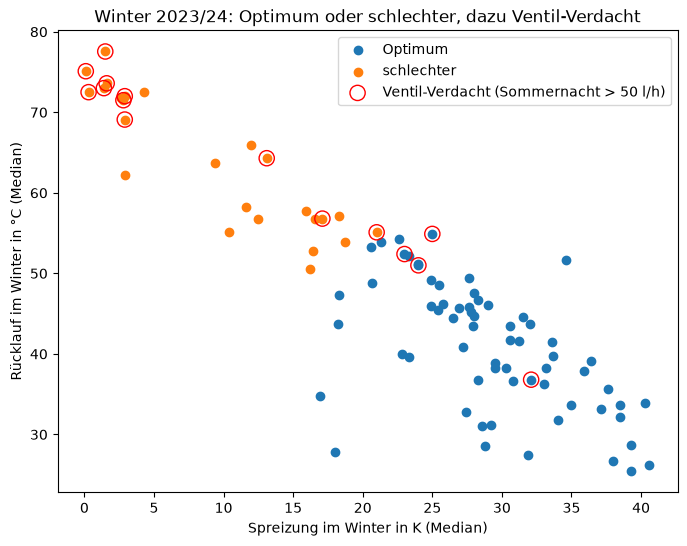

In [11]:
fig, ax = plt.subplots(figsize=(8, 6))
for name in ["Optimum", "schlechter"]:
    teil = kz[kz["einstufung"] == name]
    ax.scatter(teil["winter_spreizung"], teil["winter_ruecklauf"])
verdacht = kz[kz["ventil_verdacht"]]
ax.scatter(verdacht["winter_spreizung"], verdacht["winter_ruecklauf"], facecolors="none", edgecolors="red", s=120)
ax.set_title("Winter 2023/24: Optimum oder schlechter, dazu Ventil-Verdacht")
ax.set_xlabel("Spreizung im Winter in K (Median)")
ax.set_ylabel("Rücklauf im Winter in °C (Median)")
ax.legend(["Optimum", "schlechter", "Ventil-Verdacht (Sommernacht > 50 l/h)"])

In [12]:
fig.savefig(BILDER / "23_optimum_schlechter.png", bbox_inches="tight")

Fast alle Ventil-Verdachtsfälle liegen oben links, also in der Gruppe „schlechter“. Das passt zu Phase B: Beim Ventil kommt der Rücklauf heiß zurück. Deshalb wird das Ventil zuerst geprüft, sonst würde ein kaputtes Ventil als „Regelparameter optimieren“ eingestuft.

Gegenprobe an den begangenen Stationen: Hängt „schlechter“ mit einem Befund zusammen? Für jede Befundart eine Vierfeldertafel mit Fisher-Test (wie in Notebook 28). Sechs Tests auf einmal, also ist bei einem p knapp unter 0,05 Vorsicht angebracht.

In [13]:
gegenprobe = kz[kz["begangen"]].dropna(subset=["einstufung"]).join(labels.set_index("zaehler"))
zeilen = []
for b in ["ventil", "daemmung", "filter", "durchfluss", "temperatur", "ueberdimensioniert"]:
    t = gegenprobe.dropna(subset=[b])
    tafel = pd.crosstab(t["einstufung"] == "schlechter", t[b].astype(bool))
    zeilen.append({
        "befund": b,
        "anteil_optimum": t.loc[t["einstufung"] == "Optimum", b].astype(bool).mean(),
        "anteil_schlechter": t.loc[t["einstufung"] == "schlechter", b].astype(bool).mean(),
        "p": fisher_exact(tafel)[1],
    })
pd.DataFrame(zeilen).round(2)

,befund,anteil_optimum,anteil_schlechter,p
0,ventil,0.12,0.46,0.02
1,daemmung,0.41,0.38,1.00
2,filter,0.44,0.54,0.75
3,durchfluss,0.32,0.46,0.51
4,temperatur,0.61,0.69,0.75
5,ueberdimensioniert,0.20,0.40,0.39


- „Schlechter“ hat deutlich mehr Ventilbefunde (46 % gegen 12 %, p = 0,02), wie im Team (Notebook 28: 56 % gegen 13 %, p = 0,012). Bei sechs Tests ist p = 0,02 aber nicht ganz sicher.
- Bei allen anderen Befunden kein Unterschied. Auch Durchfluss und Temperatur, also genau die Eingriffe an den Regelparametern, hängen nicht mit „schlechter“ zusammen. „Regelparameter optimieren“ heißt deshalb: Hier ist Luft nach oben. Es heißt nicht, dass der Techniker dort Regelparameter geändert hat. Dass die Befunde Durchfluss und Temperatur kaum in den Daten zu sehen sind, wissen wir seit Phase A.

## Schritt 24: Zusammensetzen, Alarm dazu, Vergleich mit dem Team

Die Klasse nach Folie 5, in dieser Reihenfolge:

1. Ventil-Verdacht → **Regelventil tauschen**
2. sonst „schlechter“ → **Regelparameter optimieren**
3. sonst „Optimum“ → **kein Handlungsbedarf**
4. ohne Winterdaten und ohne Ventil-Verdacht → **nicht einstufbar**

In [14]:
kz["klasse"] = np.select(
    [kz["ventil_verdacht"], kz["einstufung"] == "schlechter", kz["einstufung"] == "Optimum"],
    ["Regelventil tauschen", "Regelparameter optimieren", "kein Handlungsbedarf"],
    "nicht einstufbar")
pd.crosstab(kz["klasse"], kz["begangen"], margins=True)

begangen,False,True,All
klasse,,,
Regelparameter optimieren,7,7,14
Regelventil tauschen,7,9,16
kein Handlungsbedarf,23,38,61
nicht einstufbar,3,2,5
All,40,56,96


61 × kein Handlungsbedarf, 14 × Regelparameter optimieren, 16 × Regelventil tauschen, 5 nicht einstufbar (ohne Winterdaten).

Dazu der **Alarm** aus Phase F: derselbe Wächter (7-Tage-Mittel, Fenster von 8 Wochen, |z| ≥ 5 im Rücklauf oder Durchfluss), gezählt im Jahr vor dem Stichtag (September 2023 bis August 2024). Erst die Tagesmittel wie in Schritt 20:

In [15]:
zeilen = []
for datei in sorted(METER_DIR.glob("*.csv")):
    d = pd.read_csv(datei, parse_dates=["Timestamp"])
    d = d[(d["Timestamp"] >= "2022-11-01") & (d["Timestamp"] < "2024-09-01")]
    d["tag"] = d["Timestamp"].dt.normalize()
    d["stunde"] = d["Timestamp"].dt.hour
    rl_tag = d.pivot(index="tag", columns="stunde", values="Return temperature (°C)")
    fl_tag = d.pivot(index="tag", columns="stunde", values="Volume flow (l/h)")
    voll = rl_tag.notna().all(axis=1) & fl_tag.notna().all(axis=1)
    zeilen.append(pd.DataFrame({"zaehler": int(datei.stem), "rl": rl_tag.mean(axis=1), "fl": fl_tag.mean(axis=1)})[voll])
tage = pd.concat(zeilen).reset_index()

In [16]:
for kanal in ["rl", "fl"]:
    zwerte = np.full(len(tage), np.nan)
    for z, gruppe in tage.groupby("zaehler"):
        s = gruppe.set_index("tag")[kanal].asfreq("D")
        differenz = s - s.rolling(7).mean().shift(1)
        mittel = differenz.rolling(56, min_periods=28).mean().shift(1)
        streuung = differenz.rolling(56, min_periods=28).std().shift(1)
        zwerte[gruppe.index] = ((differenz - mittel) / streuung).loc[gruppe["tag"]].values
    tage["z_" + kanal] = zwerte
tage["alarm"] = (tage["z_rl"].abs() >= 5) | (tage["z_fl"].abs() >= 5)

In [17]:
letztes_jahr = tage[tage["tag"] >= "2023-09-01"]
kz["alarme"] = letztes_jahr.groupby("zaehler")["alarm"].sum().reindex(kz.index)
kz["tage_ueberwacht"] = letztes_jahr.groupby("zaehler")["z_rl"].count().reindex(kz.index)
kz.groupby("klasse")[["alarme", "tage_ueberwacht"]].mean().round(1)

,alarme,tage_ueberwacht
klasse,,
Regelparameter optimieren,1.6,273.4
Regelventil tauschen,2.8,264.4
kein Handlungsbedarf,0.9,271.0
nicht einstufbar,0.7,299.3


Stationen mit Ventil-Verdacht hatten im Jahr vor dem Stichtag im Schnitt 2,8 Alarmtage, Stationen ohne Handlungsbedarf 0,9, bei ungefähr gleich vielen überwachten Tagen. Der Wächter schlägt also bei unruhigen Stationen öfter an.

Haben Stationen mit Befund mehr Alarme?

In [18]:
mit_labels = kz[kz["begangen"]].join(labels.set_index("zaehler")["ventil"])
mit_labels.groupby("ventil")["alarme"].agg(["mean", "count"]).round(2)

,mean,count
ventil,,
False,1.4,43
True,2.0,11


Mit Ventilbefund 2,0 Alarmtage, ohne 1,4, also nur ein kleiner Unterschied. Ein Ventil, das schon lange offen steht, ist für den Wächter normal (Phase F). Der Alarm ersetzt die Klasse deshalb nicht, sondern ergänzt sie: Die **Klasse** sagt, wo etwas dauerhaft nicht stimmt, der **Alarm**, wo sich gerade etwas verändert.

Die fertige Tabelle, gespeichert für den Report:

In [19]:
ergebnis = kz[["begangen", "anschluss_kw", "ausserhalb", "nachtfluss", "winter_ruecklauf", "winter_spreizung",
              "ventil_verdacht", "einstufung", "klasse", "alarme", "tage_ueberwacht"]]
ergebnis.to_csv(LERNPFAD / "folie5_je_station.csv")
ergebnis.head()

,begangen,anschluss_kw,ausserhalb,nachtfluss,winter_ruecklauf,winter_spreizung,ventil_verdacht,einstufung,klasse,alarme,tage_ueberwacht
zaehler,,,,,,,,,,,
41704231,False,NaN,True,0.0,37.0,NaN,False,NaN,nicht einstufbar,0.0,341.0
41704232,False,NaN,True,0.0,38.4,NaN,False,NaN,nicht einstufbar,0.0,341.0
53198226,False,20.0,False,10.0,44.6,31.5,False,Optimum,kein Handlungsbedarf,1.0,259.0
58177363,False,NaN,True,NaN,41.7,30.6,False,Optimum,kein Handlungsbedarf,1.0,223.0
58177384,False,NaN,True,NaN,49.2,24.9,False,Optimum,kein Handlungsbedarf,0.0,50.0


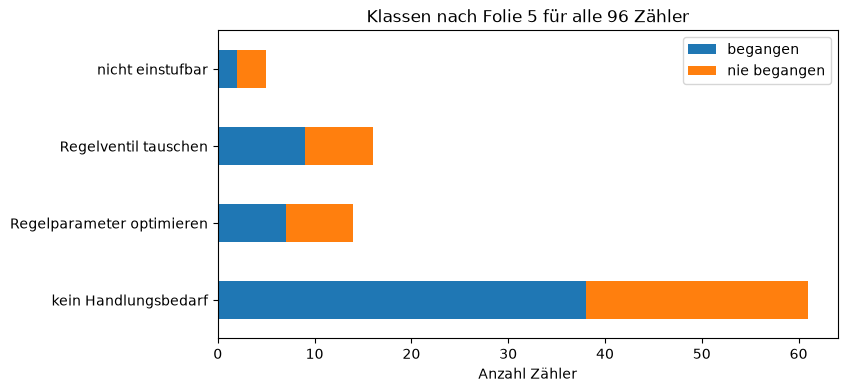

In [20]:
zaehlung = pd.crosstab(kz["klasse"], kz["begangen"].map({True: "begangen", False: "nie begangen"}))
zaehlung = zaehlung.loc[["kein Handlungsbedarf", "Regelparameter optimieren", "Regelventil tauschen", "nicht einstufbar"]]
ax = zaehlung.plot.barh(stacked=True, figsize=(8, 4))
ax.set_title("Klassen nach Folie 5 für alle 96 Zähler")
ax.set_xlabel("Anzahl Zähler")
ax.set_ylabel("")
ax.legend(["begangen", "nie begangen"])

In [21]:
ax.figure.savefig(BILDER / "24_klassen_folie5.png", bbox_inches="tight")

### Vergleich mit dem Team (Notebook 31)

In [22]:
team = pd.read_csv(ROOT / "data" / "processed" / "fehlerklassen_je_hast.csv", index_col="zaehler")
vergleich = pd.crosstab(kz["klasse"], team["klasse"].reindex(kz.index), margins=True)
vergleich

klasse,Regelparameter optimieren,Regelventil tauschen,kein Handlungsbedarf,nicht einstufbar,All
klasse,,,,,
Regelparameter optimieren,6,1,7,0,14
Regelventil tauschen,0,15,1,0,16
kein Handlungsbedarf,2,5,54,0,61
nicht einstufbar,0,0,0,5,5
All,8,21,62,5,96


In [23]:
gleich = (kz["klasse"] == team["klasse"].reindex(kz.index)).mean()
print("gleiche Klasse:", round(gleich * 100), "% der Zähler")
print("gleiche Einstufung Optimum/schlechter wie Notebook 19:",
      round((kz["einstufung"] == pd.read_csv(ROOT / "data" / "processed" / "kmeans_einstufung.csv", index_col="zaehler")["einstufung"].reindex(kz.index)).sum()), "von", kz["einstufung"].notna().sum())

gleiche Klasse: 83 % der Zähler
gleiche Einstufung Optimum/schlechter wie Notebook 19: 75 von 90


In [24]:
team_ventil = team["klasse"].reindex(kz.index) == "Regelventil tauschen"
pruefung = kz[kz["begangen"]].join(labels.set_index("zaehler")["ventil"])
pruefung["team_ventil"] = team_ventil
print("Lernpfad: Ventil-Klasse", int(pruefung["ventil_verdacht"].sum()), "davon mit Ventilbefund", int((pruefung["ventil_verdacht"] & pruefung["ventil"]).sum()))
print("Team:     Ventil-Klasse", int(pruefung["team_ventil"].sum()), "davon mit Ventilbefund", int((pruefung["team_ventil"] & pruefung["ventil"]).sum()))
print("Ventilbefunde insgesamt:", int(pruefung["ventil"].sum()))

Lernpfad: Ventil-Klasse 9 davon mit Ventilbefund 7
Team:     Ventil-Klasse 12 davon mit Ventilbefund 8
Ventilbefunde insgesamt: 11


- **83 % der Zähler bekommen dieselbe Klasse wie im Team**, „Optimum oder schlechter“ stimmt bei 75 von 90 überein.
- **Ventil:** Das Team hat 21 Zähler in der Ventil-Klasse, wir 16. Sein Ventil-Modell ist gelernt (Kennzahlen und LSTM) und schlägt auch bei 10 bis 48 l/h Nachtdurchfluss an. An den begangenen Stationen hat es dadurch eine Station mehr richtig (72135442, nachts nur 30 l/h), aber auch mehr Fehlalarme: 8 richtige von 12 gegen 7 von 9 bei uns.
- **Regelparameter optimieren:** Wir haben 7 Zähler mehr in dieser Klasse, die das Team als „kein Handlungsbedarf“ einstuft. Unser K-Means nimmt Rücklauf und Spreizung, das Team Durchflussanteil, Streubreite und lastgewichteten Rücklauf. Die 7 liegen mit 50 bis 58 °C Rücklauf genau an der Grenze zwischen den Gruppen. Für Grenzfälle ist die Einstufung unsicher, das hat auch Notebook 28 festgestellt.
- Die 5 nicht einstufbaren Zähler sind bei beiden dieselben.

## Ergebnis Phase G

| | Lernpfad | Team (Notebook 31) |
|---|---|---|
| kein Handlungsbedarf | 61 | 62 |
| Regelparameter optimieren | 14 | 8 |
| Regelventil tauschen | 16 | 21 |
| nicht einstufbar | 5 | 5 |
| gleiche Klasse | 83 % der Zähler | |

- **Fehler unterteilen nach Folie 5** geht für alle 96 Zähler mit zwei einfachen Bausteinen: der Nachtdurchfluss-Regel aus Phase B fürs Ventil und K-Means auf Winter-Rücklauf und Spreizung für „Optimum oder schlechter“.
- **Das Ventil ist belastbar** (7 von 9 richtig an den begangenen Stationen). Unter den nie begangenen gibt es 4 klare Kandidaten, 3 weitere sollte man erst in den Daten ansehen.
- **„Regelparameter optimieren“ zeigt, wo Luft nach oben ist**, passt aber zu keinem Befund. Die Eingriffe an Durchfluss und Sollwert sieht man in den Daten kaum.
- **Der Alarm aus Phase F ergänzt die Klasse:** Die Klasse beschreibt den Dauerzustand, der Wächter meldet Veränderungen.
- Die Tabelle steht in `data/processed/lernpfad/folie5_je_station.csv`.